In [ ]:
print("Crop Disease Classification Project")
print("Member 2 - Disease Classification")
print("Using MobileNetV2")

Crop Disease Classification Project
Member 2 - Disease Classification
Using MobileNetV2


In [ ]:
!pip install tensorflow

In [ ]:
import tensorflow as tf

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


In [ ]:
!pip install tensorflow-datasets

In [ ]:
import tensorflow_datasets as tfds

dataset, info = tfds.load(
    "plant_village",
    split="train",
    as_supervised=True,
    with_info=True
)

print("Dataset loaded successfully!")
print("Total images:", info.splits["train"].num_examples)
print("Number of classes:", info.features["label"].num_classes)

ModuleNotFoundError: No module named 'importlib_resources'

In [ ]:
!pip install -q importlib-resources

In [ ]:
import importlib_resources

print("Library installed successfully!")

Library installed successfully!


In [ ]:
import tensorflow_datasets as tfds

dataset, info = tfds.load(
    "plant_village",
    split="train",
    as_supervised=True,
    with_info=True
)

print("Dataset loaded successfully!")
print("Total images:", info.splits["train"].num_examples)
print("Number of classes:", info.features["label"].num_classes)

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Extraction completed...: 0 file [00:00, ? file/s]

Generating splits...:   0%|          | 0/1 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/plant_village/incomplete.WSW3JL_1.0.2/plant_village-train.tfrecord-[0-9][0…

Dataset plant_village downloaded and prepared to /root/tensorflow_datasets/plant_village/1.0.2. Subsequent calls will reuse this data.
Dataset loaded successfully!
Total images: 54303
Number of classes: 38


In [ ]:
class_names = info.features["label"].names

for i, name in enumerate(class_names):
    print(i, ":", name)

0 : Apple___Apple_scab
1 : Apple___Black_rot
2 : Apple___Cedar_apple_rust
3 : Apple___healthy
4 : Blueberry___healthy
5 : Cherry___healthy
6 : Cherry___Powdery_mildew
7 : Corn___Cercospora_leaf_spot Gray_leaf_spot
8 : Corn___Common_rust
9 : Corn___healthy
10 : Corn___Northern_Leaf_Blight
11 : Grape___Black_rot
12 : Grape___Esca_(Black_Measles)
13 : Grape___healthy
14 : Grape___Leaf_blight_(Isariopsis_Leaf_Spot)
15 : Orange___Haunglongbing_(Citrus_greening)
16 : Peach___Bacterial_spot
17 : Peach___healthy
18 : Pepper,_bell___Bacterial_spot
19 : Pepper,_bell___healthy
20 : Potato___Early_blight
21 : Potato___healthy
22 : Potato___Late_blight
23 : Raspberry___healthy
24 : Soybean___healthy
25 : Squash___Powdery_mildew
26 : Strawberry___healthy
27 : Strawberry___Leaf_scorch
28 : Tomato___Bacterial_spot
29 : Tomato___Early_blight
30 : Tomato___healthy
31 : Tomato___Late_blight
32 : Tomato___Leaf_Mold
33 : Tomato___Septoria_leaf_spot
34 : Tomato___Spider_mites Two-spotted_spider_mite
35 : To

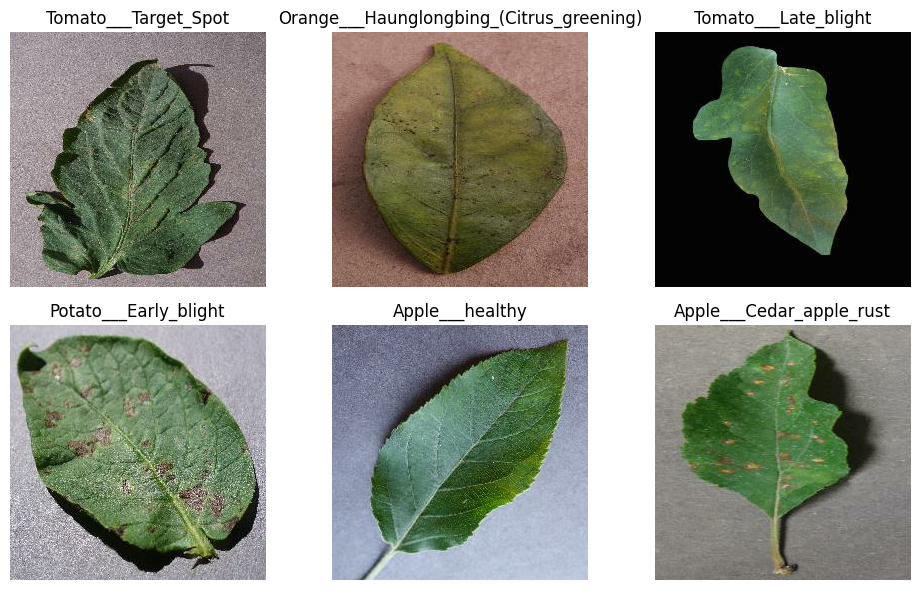

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

for i, (image, label) in enumerate(dataset.take(6)):
    plt.subplot(2, 3, i + 1)
    plt.imshow(image.numpy())
    plt.title(class_names[label.numpy()])
    plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
train_data, val_data, test_data = tfds.load(
    "plant_village",
    split=[
        "train[:70%]",
        "train[70%:85%]",
        "train[85%:]"
    ],
    as_supervised=True
)

print("Dataset split successfully!")
print("Training dataset ready")
print("Validation dataset ready")
print("Testing dataset ready")

Dataset split successfully!
Training dataset ready
Validation dataset ready
Testing dataset ready


In [ ]:
import numpy as np

def check_classes(data):
    counts = np.zeros(38, dtype=int)

    for image, label in data:
        counts[label.numpy()] += 1

    return counts

train_counts = check_classes(train_data)
val_counts = check_classes(val_data)
test_counts = check_classes(test_data)

print("Training:", train_counts.sum(), "images")
print("Validation:", val_counts.sum(), "images")
print("Testing:", test_counts.sum(), "images")

print("Training classes:", np.count_nonzero(train_counts))
print("Validation classes:", np.count_nonzero(val_counts))
print("Testing classes:", np.count_nonzero(test_counts))

Training: 38012 images
Validation: 8146 images
Testing: 8145 images
Training classes: 38
Validation classes: 38
Testing classes: 38


In [ ]:
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

print("MobileNetV2 preprocessing imported!")

MobileNetV2 preprocessing imported!


In [ ]:
IMG_SIZE = 224
BATCH_SIZE = 32

def prepare_data(image, label):
    image = tf.image.resize(image, (IMG_SIZE, IMG_SIZE))
    image = preprocess_input(image)
    return image, label

train_data = train_data.map(
    prepare_data,
    num_parallel_calls=tf.data.AUTOTUNE
).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

val_data = val_data.map(
    prepare_data,
    num_parallel_calls=tf.data.AUTOTUNE
).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

test_data = test_data.map(
    prepare_data,
    num_parallel_calls=tf.data.AUTOTUNE
).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

print("Images prepared successfully!")

Images prepared successfully!


In [ ]:
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras import layers, models

print("MobileNetV2 imported successfully!")

MobileNetV2 imported successfully!


In [ ]:
base_model = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

base_model.trainable = False

print("MobileNetV2 loaded successfully!")

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
MobileNetV2 loaded successfully!


In [ ]:
model = models.Sequential([
    layers.Input(shape=(224, 224, 3)),
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),
    layers.Dense(38, activation="softmax")
])

print("Disease classification model created!")

Disease classification model created!


In [ ]:
model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 38)             │        48,678 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,306,662 (8.80 MB)

 Trainable params: 48,678 (190.15 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [ ]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Model compiled successfully!")

NameError: name 'model' is not defined

In [ ]:
history = model.fit(
    train_data,
    validation_data=val_data,
    epochs=5
)

NameError: name 'model' is not defined

In [1]:
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras import layers, models

base_model = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

base_model.trainable = False

model = models.Sequential([
    layers.Input(shape=(224, 224, 3)),
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),
    layers.Dense(38, activation="softmax")
])

print("Model created successfully!")

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Model created successfully!


In [2]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Model compiled successfully!")

Model compiled successfully!


In [3]:
history = model.fit(
    train_data,
    validation_data=val_data,
    epochs=5
)

NameError: name 'train_data' is not defined

In [4]:
import tensorflow as tf
import tensorflow_datasets as tfds

from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

train_data, val_data, test_data = tfds.load(
    "plant_village",
    split=[
        "train[:70%]",
        "train[70%:85%]",
        "train[85%:]"
    ],
    as_supervised=True
)

print("Datasets restored successfully!")

ModuleNotFoundError: No module named 'importlib_resources'

In [5]:
!pip install -q importlib-resources

In [6]:
import importlib_resources

print("Library ready!")

Library ready!


In [1]:
import tensorflow_datasets as tfds

train_data, val_data, test_data = tfds.load(
    "plant_village",
    split=[
        "train[:70%]",
        "train[70%:85%]",
        "train[85%:]"
    ],
    as_supervised=True
)

print("Datasets restored!")

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Extraction completed...: 0 file [00:00, ? file/s]

Generating splits...:   0%|          | 0/1 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/plant_village/incomplete.O5FLGS_1.0.2/plant_village-train.tfrecord-[0-9][0…

Dataset plant_village downloaded and prepared to /root/tensorflow_datasets/plant_village/1.0.2. Subsequent calls will reuse this data.
Datasets restored!


In [2]:
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

IMG_SIZE = 224
BATCH_SIZE = 32

def prepare_data(image, label):
    image = tf.image.resize(image, (IMG_SIZE, IMG_SIZE))
    image = preprocess_input(image)
    return image, label

train_data = train_data.map(prepare_data).batch(32).prefetch(tf.data.AUTOTUNE)

val_data = val_data.map(prepare_data).batch(32).prefetch(tf.data.AUTOTUNE)

test_data = test_data.map(prepare_data).batch(32).prefetch(tf.data.AUTOTUNE)

print("All datasets prepared successfully!")

NameError: in user code:

    File "/tmp/ipykernel_2760/892521163.py", line 7, in prepare_data  *
        image = tf.image.resize(image, (IMG_SIZE, IMG_SIZE))

    NameError: name 'tf' is not defined


In [3]:
import tensorflow as tf

print("TensorFlow imported successfully!")

TensorFlow imported successfully!


In [4]:
IMG_SIZE = 224
BATCH_SIZE = 32

def prepare_data(image, label):
    image = tf.image.resize(image, (IMG_SIZE, IMG_SIZE))
    image = preprocess_input(image)
    return image, label

train_data = train_data.map(prepare_data).batch(32).prefetch(tf.data.AUTOTUNE)

val_data = val_data.map(prepare_data).batch(32).prefetch(tf.data.AUTOTUNE)

test_data = test_data.map(prepare_data).batch(32).prefetch(tf.data.AUTOTUNE)

print("All datasets prepared successfully!")

All datasets prepared successfully!


In [5]:
for images, labels in train_data.take(1):
    print(images.shape)
    print(labels.shape)

(32, 224, 224, 3)
(32,)


In [6]:
import numpy as np

def check_classes(data):
    counts = np.zeros(38, dtype=int)

    for images, labels in data:
        counts += np.bincount(
            labels.numpy(), minlength=38
        )

    return counts

train_counts = check_classes(train_data)
val_counts = check_classes(val_data)
test_counts = check_classes(test_data)

print("Training classes:", np.count_nonzero(train_counts))
print("Validation classes:", np.count_nonzero(val_counts))
print("Testing classes:", np.count_nonzero(test_counts))

Training classes: 38
Validation classes: 38
Testing classes: 38


In [7]:
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2

base_model = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

base_model.trainable = False

model = models.Sequential([
    layers.Input(shape=(224, 224, 3)),
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),
    layers.Dense(38, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Model ready for training!")

Model ready for training!


In [8]:
from tensorflow.keras.callbacks import ModelCheckpoint

checkpoint = ModelCheckpoint(
    "classifier.keras",
    monitor="val_accuracy",
    save_best_only=True,
    mode="max"
)

history = model.fit(
    train_data,
    validation_data=val_data,
    epochs=5,
    callbacks=[checkpoint]
)

Epoch 1/5
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 2115s 2s/step - accuracy: 0.8591 - loss: 0.5133 - val_accuracy: 0.9308 - val_loss: 0.2256
Epoch 2/5
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 2043s 2s/step - accuracy: 0.9347 - loss: 0.2124 - val_accuracy: 0.9450 - val_loss: 0.1741
Epoch 3/5
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 1975s 2s/step - accuracy: 0.9458 - loss: 0.1701 - val_accuracy: 0.9478 - val_loss: 0.1598
Epoch 4/5
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 1985s 2s/step - accuracy: 0.9505 - loss: 0.1524 - val_accuracy: 0.9437 - val_loss: 0.1657
Epoch 5/5
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 1981s 2s/step - accuracy: 0.9541 - loss: 0.1406 - val_accuracy: 0.9476 - val_loss: 0.1606


In [9]:
best_model = tf.keras.models.load_model("classifier.keras")

test_loss, test_accuracy = best_model.evaluate(test_data)

print("Test Accuracy:", test_accuracy * 100, "%")
print("Test Loss:", test_loss)

255/255 ━━━━━━━━━━━━━━━━━━━━ 367s 1s/step - accuracy: 0.9546 - loss: 0.1463
Test Accuracy: 95.45733332633972 %
Test Loss: 0.14627230167388916


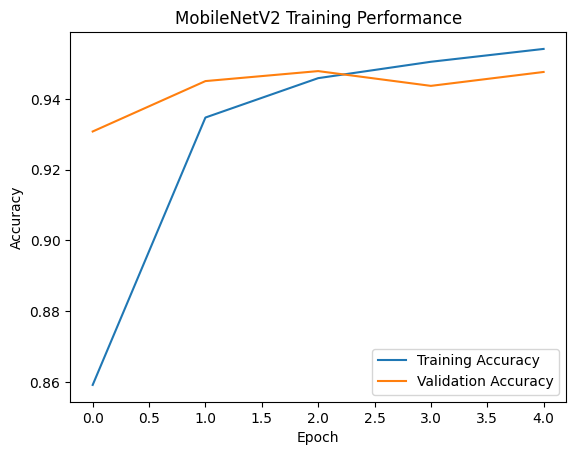

In [10]:
import matplotlib.pyplot as plt

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("MobileNetV2 Training Performance")

plt.legend()
plt.show()

In [11]:
best_model.save("classifier.keras")

print("Classification model saved successfully!")

Classification model saved successfully!


In [12]:
best_model = tf.keras.models.load_model("classifier.keras")

test_loss, test_accuracy = best_model.evaluate(test_data)

print("Test Accuracy:", test_accuracy * 100, "%")
print("Test Loss:", test_loss)

255/255 ━━━━━━━━━━━━━━━━━━━━ 363s 1s/step - accuracy: 0.9546 - loss: 0.1463
Test Accuracy: 95.45733332633972 %
Test Loss: 0.14627230167388916


In [13]:
import json

class_names = info.features["label"].names

with open("class_names.json", "w") as f:
    json.dump(class_names, f)

print("Disease names saved successfully!")

NameError: name 'info' is not defined

In [15]:
import tensorflow_datasets as tfds
import json

info = tfds.builder("plant_village").info

class_names = info.features["label"].names

with open("class_names.json", "w") as f:
    json.dump(class_names, f)

print("Disease names saved successfully!")
print("Total disease classes:", len(class_names))

Disease names saved successfully!
Total disease classes: 38


In [16]:
import os

print("Model:", os.path.exists("classifier.keras"))
print("Disease names:", os.path.exists("class_names.json"))

Model: True
Disease names: True


In [17]:
from google.colab import drive
drive.mount('/content/drive')

import shutil
import os

folder = "/content/drive/MyDrive/Crop_Disease_Classification"

os.makedirs(folder, exist_ok=True)

shutil.copy2("classifier.keras", folder)
shutil.copy2("class_names.json", folder)

print("Both files backed up successfully!")

Mounted at /content/drive
Both files backed up successfully!


In [19]:
%%writefile /content/drive/MyDrive/Crop_Disease_Classification/prediction.py

import os
import json
import numpy as np
import tensorflow as tf

from PIL import Image
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

BASE_DIR = os.path.dirname(os.path.abspath(__file__))

MODEL_PATH = os.path.join(BASE_DIR, "classifier.keras")
CLASS_PATH = os.path.join(BASE_DIR, "class_names.json")

model = tf.keras.models.load_model(MODEL_PATH)

with open(CLASS_PATH, "r") as f:
    class_names = json.load(f)


def predict_disease(image_path):

    image = Image.open(image_path).convert("RGB")
    image = image.resize((224, 224))

    image = np.array(image, dtype=np.float32)
    image = preprocess_input(image)

    image = np.expand_dims(image, axis=0)

    predictions = model.predict(image, verbose=0)

    index = np.argmax(predictions[0])

    disease = class_names[index]
    confidence = float(predictions[0][index] * 100)

    return disease, confidence

Overwriting /content/drive/MyDrive/Crop_Disease_Classification/prediction.py


In [20]:
import os

folder = "/content/drive/MyDrive/Crop_Disease_Classification"

print(os.listdir(folder))

['classifier.keras', 'class_names.json', 'prediction.py']


In [22]:
import sys

folder = "/content/drive/MyDrive/Crop_Disease_Classification"

sys.path.append(folder)

from prediction import predict_disease

from google.colab import files

uploaded = files.upload()

image_path = list(uploaded.keys())[0]

disease, confidence = predict_disease(image_path)

print("Predicted Disease:", disease)
print("Confidence:", round(confidence, 2), "%")

Saving IMG_1854.png to IMG_1854.png
Predicted Disease: Pepper,_bell___Bacterial_spot
Confidence: 60.22 %


In [24]:
import os
print(os.listdir("/content"))

['.config', 'IMG_1854.png', 'drive', 'class_names.json', 'classifier.keras', 'sample_data']


In [25]:
import os
import json
import shutil

folder = "/content/drive/MyDrive/Crop_Disease_Classification"

os.makedirs(folder, exist_ok=True)

# Copy trained model
shutil.copy("/content/classifier.keras", folder)

# Copy disease names
shutil.copy("/content/class_names.json", folder)

# Create prediction.py
code = '''
import tensorflow as tf
import numpy as np
import json

from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from tensorflow.keras.preprocessing import image

model = tf.keras.models.load_model("classifier.keras")

with open("class_names.json", "r") as f:
    class_names = json.load(f)

def predict_disease(image_path):

    img = image.load_img(image_path, target_size=(224, 224))
    img = image.img_to_array(img)

    img = np.expand_dims(img, axis=0)
    img = preprocess_input(img)

    predictions = model.predict(img, verbose=0)

    index = np.argmax(predictions[0])

    disease = class_names[index]
    confidence = float(predictions[0][index] * 100)

    return disease, confidence
'''

with open(folder + "/prediction.py", "w") as f:
    f.write(code)

print("All three deliverables saved successfully!")
print(os.listdir(folder))

All three deliverables saved successfully!
['classifier.keras', 'class_names.json', 'prediction.py', '__pycache__']


In [26]:
import sys

sys.path.insert(0, folder)

from prediction import predict_disease

print("Prediction function imported successfully!")

Prediction function imported successfully!


In [27]:
import sys
import importlib

sys.path.insert(0, folder)

import prediction
importlib.reload(prediction)

disease, confidence = prediction.predict_disease("/content/IMG_1854.png")

print("Predicted Disease:", disease)
print("Confidence:", round(confidence, 2), "%")

Predicted Disease: Tomato___Septoria_leaf_spot
Confidence: 54.59 %
